# Study 09 · 02 · E1 · Main comparison over 18 seasons

**Question.** Does adding the b3 climate block (temperature, humidity, rainfall, Niño 1+2) to case history and geography improve Brier at 2–4 weeks, when weather is limited to what was published at the origin (lag 2)?

**Protocol.**
- Primary: the 18 complete seasons 2009–2026, pooled over district-weeks (ratio of summed squared errors per seed, then the median over seeds).
- Always shown with it: the equal-season mean, skill vs probabilistic persistence and vs climatology, and whole-season bootstrap intervals (20,000 draws, seeds paired).
- Margin (D1): 1% relative four-week Brier. "No measurable gain" means the interval excludes improvements larger than 1%.
- Sensitivities: the six decision seasons (must match Table II) and leave-one-season-out.

Arms: `b3_obs` and `historia_geo` (fixed hyperparameters; reproduced exactly in notebook 01). Negative change favours the first arm.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import experiments as ex

FIG = STUDY / "figures"
RES = c.OUTPUT / "resultados"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
b3 = c.read_arm("b3_obs", columns=ex.PRED_COLUMNS)
hg = c.read_arm("historia_geo", columns=ex.PRED_COLUMNS)
base = pd.read_csv(c.OUTPUT / "baselines.csv.gz", dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])
s_b3, s_hg = ex.sse(b3), ex.sse(hg)
s_pp, s_cl = ex.sse(base, "persistencia_prob"), ex.sse(base, "climatologia")
print("rows per horizon and seed:", s_b3[s_b3.semilla.eq(17)].groupby("horizonte").n.sum().to_dict(),
      "| elevated weeks:", s_b3[s_b3.semilla.eq(17)].groupby("horizonte").eventos.sum().to_dict())

rows per horizon and seed: {2: 61100, 3: 61100, 4: 61100} | elevated weeks: {2: 4627, 3: 4627, 4: 4627}


## 1 · Primary result: 18 seasons

In [2]:
def table(a, b, name):
    t = ex.contrast(a, b)
    return t.assign(comparacion=name)[["comparacion", *t.columns]]

main = pd.concat([table(s_b3, s_hg, "b3 vs history+geography (climate effect)"),
                  table(s_b3, s_pp, "b3 vs probabilistic persistence"),
                  table(s_hg, s_pp, "history+geography vs probabilistic persistence"),
                  table(s_b3, s_cl, "b3 vs climatology"), table(s_hg, s_cl, "history+geography vs climatology")])
main.to_csv(RES / "e1_principal_18_temporadas.csv", index=False)
main.round(4)

,comparacion,horizonte,temporadas,brier_a,brier_b,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,ic95_igual_peso,temporadas_a_mejor
0,b3 vs history+geography (climate effect),2,18,0.0282,0.0283,-0.4300,"(-1.46, 0.37)",-1.3127,"(-2.93, 0.11)",10
1,b3 vs history+geography (climate effect),3,18,0.0322,0.0323,-0.2760,"(-1.89, 0.87)",-1.3944,"(-3.76, 0.72)",10
2,b3 vs history+geography (climate effect),4,18,0.0356,0.0356,0.0416,"(-2.31, 1.7)",-1.1533,"(-4.25, 1.76)",10
0,b3 vs probabilistic persistence,2,18,0.0282,0.0286,-1.4220,"(-4.96, 3.61)",9.1945,"(1.5, 17.87)",8
1,b3 vs probabilistic persistence,3,18,0.0322,0.0332,-3.2186,"(-7.25, 3.06)",7.6815,"(0.01, 16.25)",8
2,b3 vs probabilistic persistence,4,18,0.0356,0.0374,-4.7638,"(-9.18, 2.38)",8.6167,"(-1.01, 19.36)",9
0,history+geography vs probabilistic persistence,2,18,0.0283,0.0286,-0.9845,"(-4.58, 4.48)",11.0241,"(2.07, 21.11)",7
1,history+geography vs probabilistic persistence,3,18,0.0323,0.0332,-2.9507,"(-7.38, 4.37)",10.0764,"(0.53, 21.0)",7
2,history+geography vs probabilistic persistence,4,18,0.0356,0.0374,-4.8032,"(-10.08, 4.02)",10.9122,"(-0.88, 24.44)",8
0,b3 vs climatology,2,18,0.0282,0.0697,-59.5196,"(-66.18, -50.0)",-55.5063,"(-63.03, -48.52)",18


In [3]:
margin = 1.0
verdict = []
for _, r in main[main.comparacion.str.startswith("b3 vs history")].iterrows():
    lo, hi = r["ic95_agrupado"]
    verdict.append({"horizonte": r.horizonte, "cambio_agrupado_%": round(r["cambio_agrupado_%"], 2), "ic95": (lo, hi),
                    "excluye mejoras > 1%": lo > -margin,
                    "lectura": "no measurable gain from climate" if lo > -margin else "a gain larger than the margin cannot be excluded"})
pd.DataFrame(verdict)

,horizonte,cambio_agrupado_%,ic95,excluye mejoras > 1%,lectura
0,2,-0.43,"(-1.46, 0.37)",False,a gain larger than the margin cannot be excluded
1,3,-0.28,"(-1.89, 0.87)",False,a gain larger than the margin cannot be excluded
2,4,0.04,"(-2.31, 1.7)",False,a gain larger than the margin cannot be excluded


## 2 · Season by season (four weeks; all horizons in the CSV)

In [4]:
seasons = ex.by_season(s_b3, s_hg)
seasons.to_csv(RES / "e1_por_temporada.csv", index=False)
seasons[seasons.horizonte.eq(4)].round(2).set_index("temporada").T

temporada,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0
horizonte,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00
prevalencia_%,5.08,6.92,0.38,1.89,2.51,1.72,14.51,9.91,15.38,2.04,0.03,0.03,2.73,13.20,30.50,25.38,1.69,2.50
cambio_%,-0.83,-0.49,-15.56,-0.36,3.07,0.98,1.12,0.79,3.87,-16.32,12.88,-4.78,-1.48,3.09,2.95,-1.99,-5.72,-1.98


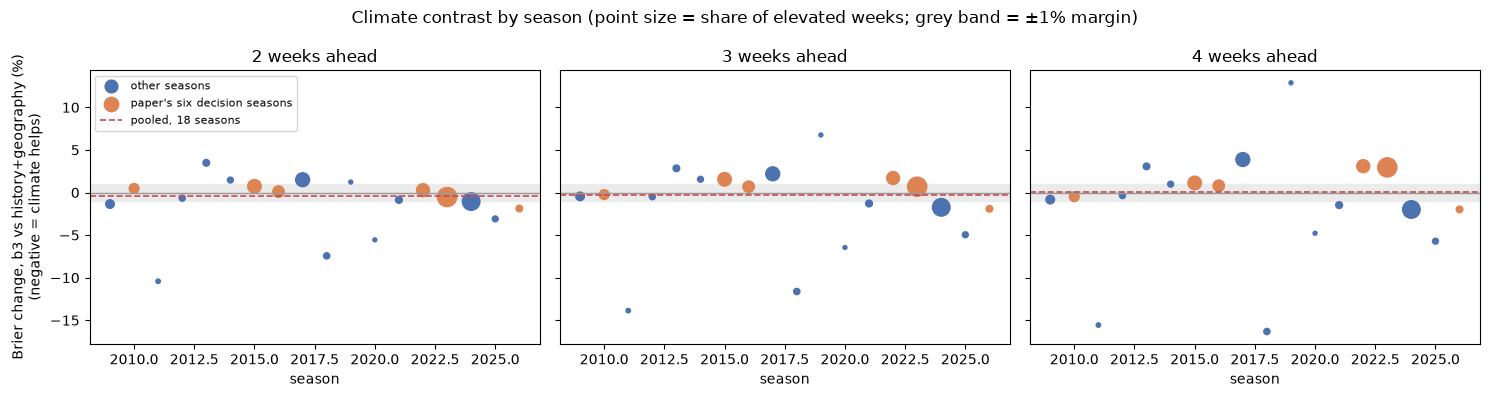

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, h in zip(axes, (2, 3, 4)):
    d = seasons[seasons.horizonte.eq(h)]
    decision = d.temporada.isin(c.DECISION_SEASONS)
    ax.axhline(0, color="0.6", lw=1)
    ax.axhspan(-margin, margin, color="0.92", zorder=0)
    ax.scatter(d.temporada[~decision], d["cambio_%"][~decision], s=8 + 6 * d["prevalencia_%"][~decision], color="#4C72B0",
               label="other seasons")
    ax.scatter(d.temporada[decision], d["cambio_%"][decision], s=8 + 6 * d["prevalencia_%"][decision], color="#DD8452",
               label="paper's six decision seasons")
    pooled = main[(main.comparacion.str.startswith("b3 vs history")) & main.horizonte.eq(h)].iloc[0]
    ax.axhline(pooled["cambio_agrupado_%"], color="#C44E52", ls="--", lw=1.2, label="pooled, 18 seasons")
    ax.set_title(f"{h} weeks ahead")
    ax.set_xlabel("season")
axes[0].set_ylabel("Brier change, b3 vs history+geography (%)\n(negative = climate helps)")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Climate contrast by season (point size = share of elevated weeks; grey band = ±1% margin)")
fig.tight_layout()
fig.savefig(FIG / "e1_contraste_por_temporada.png", dpi=160)

## 3 · Sensitivities: the six decision seasons (should reproduce Table II) and leave-one-season-out

In [6]:
six = [ex.sse(f, p, seasons=c.DECISION_SEASONS) for f, p in ((b3, "probabilidad_calibrada"), (hg, "probabilidad_calibrada"), (base, "persistencia_prob"))]
six_table = pd.concat([table(six[0], six[1], "six seasons: b3 vs history+geography"),
                       table(six[0], six[2], "six seasons: b3 vs probabilistic persistence")])
six_table.round(3)

,comparacion,horizonte,temporadas,brier_a,brier_b,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,ic95_igual_peso,temporadas_a_mejor
0,six seasons: b3 vs history+geography,2,6,0.043,0.043,-0.020,"(-0.45, 0.49)",-0.139,"(-0.9, 0.45)",2
1,six seasons: b3 vs history+geography,3,6,0.050,0.049,0.869,"(0.14, 1.37)",0.408,"(-0.63, 1.31)",2
2,six seasons: b3 vs history+geography,4,6,0.056,0.055,1.574,"(0.3, 2.45)",0.914,"(-0.51, 2.33)",2
0,six seasons: b3 vs probabilistic persistence,2,6,0.043,0.044,-3.281,"(-7.99, 3.42)",-0.494,"(-6.26, 4.85)",3
1,six seasons: b3 vs probabilistic persistence,3,6,0.050,0.052,-4.302,"(-10.28, 3.9)",-0.260,"(-7.7, 7.11)",3
2,six seasons: b3 vs probabilistic persistence,4,6,0.056,0.059,-6.371,"(-12.37, 1.78)",-2.106,"(-9.84, 5.96)",4


In [7]:
loso = ex.leave_one_out(s_b3, s_hg)
loso.to_csv(RES / "e1_omitir_una_temporada.csv", index=False)
loso[loso.horizonte.eq(4)].round(2).set_index("omitida").T

omitida,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0
horizonte,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.0
cambio_agrupado_%,0.09,0.05,0.23,0.05,-0.05,0.02,-0.12,-0.04,-0.52,0.69,0.03,0.05,0.08,-0.28,-0.39,0.42,0.19,0.1
cambio_igual_peso_%,-1.17,-1.19,-0.31,-1.20,-1.40,-1.28,-1.29,-1.27,-1.45,-0.26,-1.98,-0.94,-1.13,-1.40,-1.39,-1.10,-0.88,-1.1


## 4 · Reading

The tables above are the E1 result; the summary notebook (09) puts the numbers into words. The interval is a whole-season bootstrap, so with 18 seasons it is still coarse. Read it as the range of season mixes compatible with the data, not as a sampling interval over district-weeks.